# Klasifikacija slika - American Sign Language Dataset

Kao u prošlom *notebook*-u, proći ćemo kroz korake pripreme podataka, kreiranja modela i treninga modela. Koristićemo novi skup podataka [*American Sign Language*](http://www.asl.gs/) (ASL).

ASL skup podataka sadrži 26 slova. Dva od ovih slova (j i z) zahtevaju gest (pokret), pa nisu uključena u ovaj skup podataka.

ASL je dostupan preko [Kaggle](https://www.kaggle.com/) platforme koja sadrži mnogo korisnih skupova podataka i drugih resursa za mašinsko učenje. Na primer, uz skupove podataka postoje "kerneli" koji nalikuju ovim *notebook*-ovima. Kaggle takođe organizuje takmičenja iz mašinskog učenja.

## Učitavanje podataka

ASL skup podataka je u [CSV](https://en.wikipedia.org/wiki/Comma-separated_values) (Comma Separated Values) formatu. Da bismo učitali ovaj skup podataka, koristićemo [Pandas](https://pandas.pydata.org/) biblioteku - pomoću njene `read_csv` metode ćemo učitati CSV skup podataka u [DataFrame](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html) format.

In [1]:
import pandas as pd

train_df = pd.read_csv("./asl_data/sign_mnist_train.csv")
test_df = pd.read_csv("./asl_data/sign_mnist_valid.csv")

### Analiza i priprema podataka

Pomoću [`head`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.head.html) metode ćemo ispisati prvih nekoliko redova trening skupa podataka (DataFrame objekta). Vidimo da svaki red ima `label` kolonu i 784 vrednosti koje odgovaraju vrednostima piksela na slici. Obratite pažnju da je `label` kolona  numerička (a ne slova alfabeta).

In [2]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,12,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


Izdvojićemo labele u `y_train` i `y_valid` varijable. Kreiramo ove varijable i zatim brišemo odgovarajuće kolone iz originalnog DataFrame-a:

In [3]:
y_train = train_df['label']
y_test = test_df['label']
del train_df['label']
del test_df['label']

Preostale kolone (vrednosti intenziteta piksela) ćemo sačuvati u x_train i x_valid varijablama.

In [4]:
x_train = train_df.values
x_test = test_df.values

Trening skup: 27 455 slike, svaka opisana sa 784 vrednosti piksela:

In [5]:
x_train.shape

(27455, 784)

Odgovarajuće labele trening skupa:

In [6]:
y_train.shape

(27455,)

Test skup: 7 172 slike:

In [7]:
x_test.shape

(7172, 784)

Odgovarajuće labele test skupa:

In [8]:
y_test.shape

(7172,)

Možemo vizualizovati slike pomoću matplotlib biblioteke. Da bismo ovo uradili, moramo reshape-ovati podatke iz 1D niza nazad u 2D niz od 28 x 28 piksela:

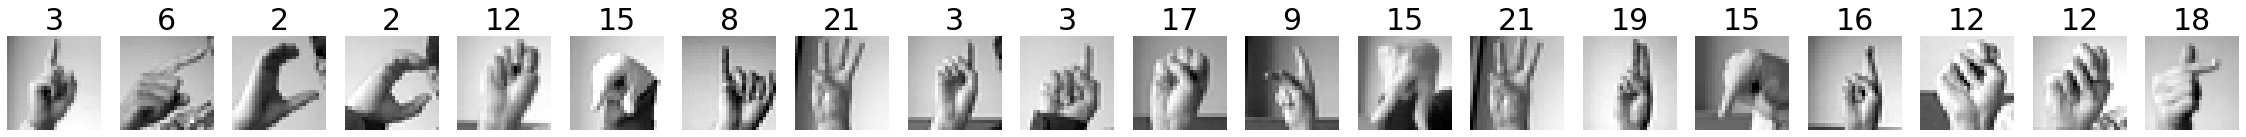

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(40,40))

num_images = 20
for i in range(num_images):
    row = x_train[i]
    label = y_train[i]
    
    image = row.reshape(28,28)
    plt.subplot(1, num_images, i+1)
    plt.title(label, fontdict={'fontsize': 30})
    plt.axis('off')
    plt.imshow(image, cmap='gray')

### Podela trening dela podataka na trening i validacioni skup:

In [10]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

### Normalizacija:

Pre normalizacije:

In [11]:
x_train.min()

0

In [12]:
x_train.max()

255

Nakon normalizacije:

In [13]:
x_train = x_train/255
x_val = x_val/255
x_test = x_test/255

In [14]:
x_train.min()

0.0

In [15]:
x_train.max()

1.0

## Ekstrakcija obeležja:

In [16]:
from skimage.feature import hog
import matplotlib.pyplot as plt
import numpy as np

def extract_hog_features(images, nbins=9, cell_size=(8, 8), block_size=(2, 2)):
    hog_features = []
    hog_images = []
    
    for image in images:
        # Ensure the image is reshaped to 2D (28x28)
        image_reshaped = image.reshape(28, 28)
        # visualize=True ->  return both the HOG features and a visualization of the HOG image.
        # channel_axis -> which axis of the input image is the channel axis (e.g., RGB). Setting channel_axis=None indicates that the input image is a grayscale image (does not have a separate channel axis).
        fd, hog_image = hog(image_reshaped, orientations=nbins, pixels_per_cell=cell_size, 
                            cells_per_block=block_size, visualize=True, channel_axis=None)
        hog_features.append(fd)
        hog_images.append(hog_image)
    return hog_features, hog_images

Tipično korišćene vrednosti parametara za HOG:

In [30]:
import pickle
import os

# Extract HOG features
hog_features_train, hog_images_train = extract_hog_features(x_train)

# Save the features to a file
with open('hog_features_train_cells_8_8.pkl', 'wb') as f:
    pickle.dump(hog_features_train, f)

# Directory for saving HOG images
hog_images_dir = 'hog_images_8_8'
if not os.path.exists(hog_images_dir):
    os.makedirs(hog_images_dir)
for i in range(len(hog_images_train)):
    hog_image = hog_images_train[i]
    plt.imsave(f"{hog_images_dir}/hog_image_{i}.png", hog_image, cmap='gray')

In [18]:
import pickle

with open('hog_features_train_cells_8_8.pkl', 'rb') as f:
    hog_features_train = pickle.load(f)

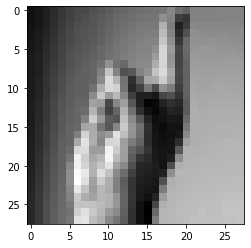

In [19]:
image_index = 1
plt.imshow(x_train[image_index].reshape(28,28), cmap='gray')

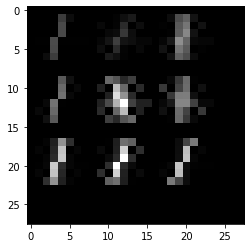

In [21]:
import matplotlib.image as mpimg

hog_images_dir = 'hog_images_8_8'
plt.imshow(mpimg.imread(f"{hog_images_dir}/hog_image_{image_index}.png"))

## Treniranje modela:

Jednostavan linearni SVM:

In [23]:
from sklearn.svm import LinearSVC
from sklearn.metrics import make_scorer, f1_score

classifier = LinearSVC()
classifier.fit(x_train, y_train)

C:\Users\slivk\anaconda3\lib\site-packages\sklearn\svm\_base.py:1206: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC()

In [24]:
from joblib import dump

dump(classifier, 'svm_linear_model.joblib')

['svm_linear_model.joblib']

In [25]:
y_train_pred = classifier.predict(x_train)
y_test_pred = classifier.predict(x_test)
print("Train F-measure: ", f1_score(y_train, y_train_pred, average='weighted'))
print("Test F-measure: ", f1_score(y_test, y_test_pred, average='weighted'))

Train F-measure:  0.9999544724678913
Train F-measure:  0.6253860344087738


In [26]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import make_scorer, f1_score

# Define the SVM model and parameter grid
model = SVC()
param_grid = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}

# Define the scorer
f1_scorer = make_scorer(f1_score, average='weighted')

# Perform grid search
grid_search = GridSearchCV(model, param_grid, scoring=f1_scorer, cv=5)
grid_search.fit(x_train, y_train)

# Best parameters
print("Best parameters:", grid_search.best_params_)

Best parameters: {'C': 1, 'kernel': 'linear'}


In [27]:
from joblib import dump

dump(classifier, 'svm_optimized_C_kernel.joblib')

['svm_optimized_C_kernel.joblib']

In [ ]:
from joblib import load

loaded_model = load('svm_optimized_C_kernel.joblib')

## Analiza grešaka modela

Tablica konfuzije (*Contingency Table*, *Confusion Matrix*):

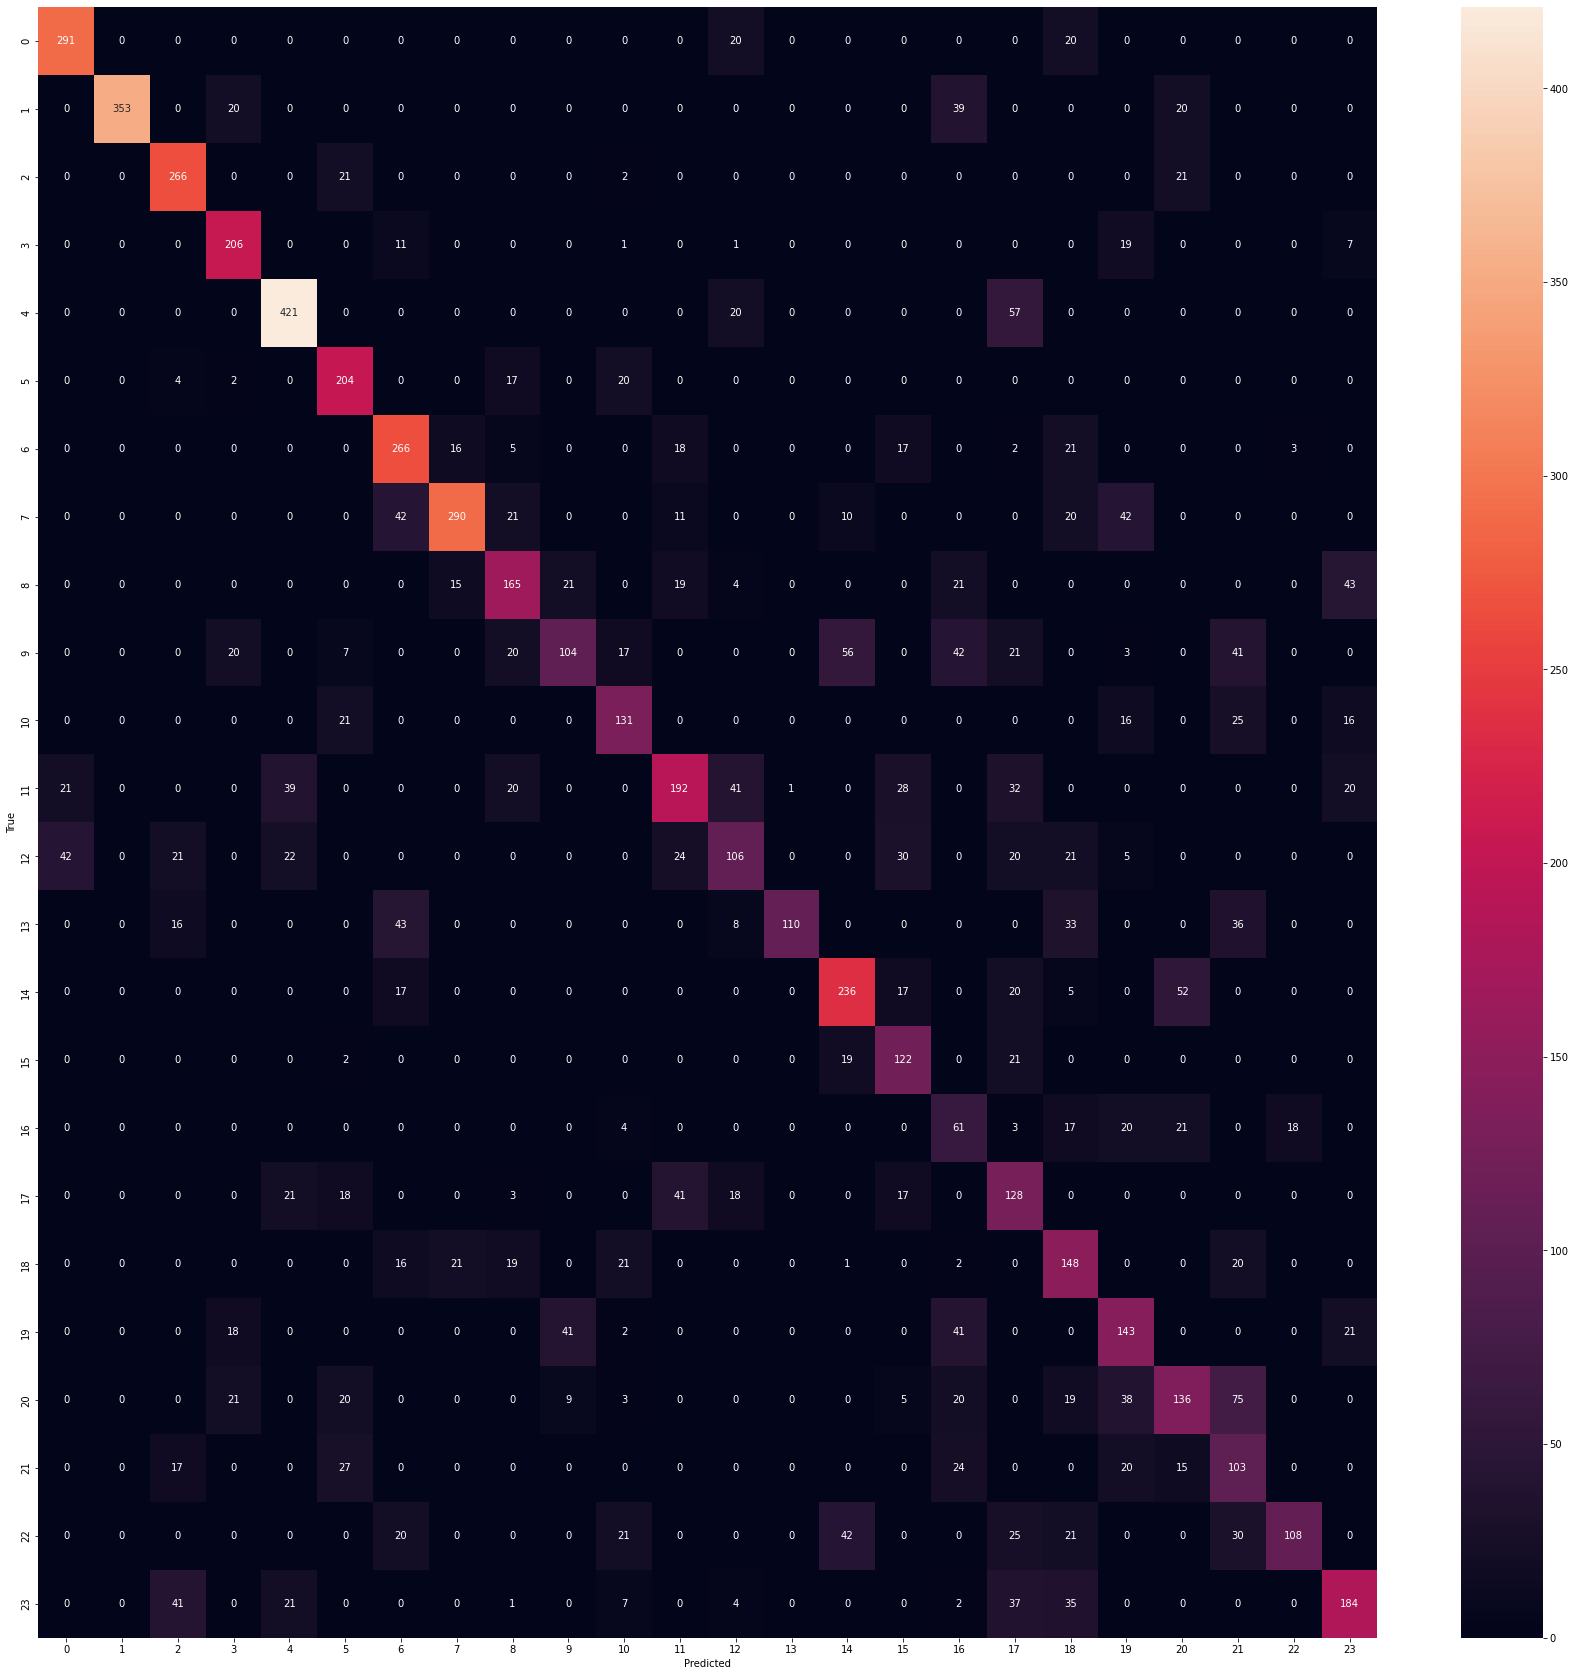

In [56]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

conf_mat = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 10))
sns.heatmap(conf_mat, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

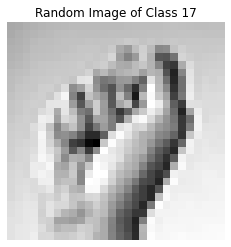

In [38]:
import matplotlib.pyplot as plt
import numpy as np

def show_random_image_of_class(X, y, class_no):
    # Filter the images of the specific class
    class_indices = np.where(y == class_no)[0]

    # Randomly select an image
    random_index = np.random.choice(class_indices)

    # Reshape the image data (assuming images are 28x28 pixels)
    image_data = X[random_index].reshape(28, 28)

    # Display the image
    plt.imshow(image_data, cmap='gray')
    plt.title(f'Random Image of Class {class_no}')
    plt.axis('off')
    plt.show()

show_random_image_of_class(x_train, y_train, 17)

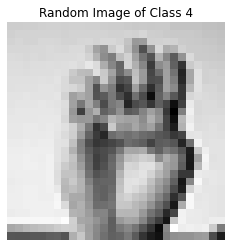

In [39]:
show_random_image_of_class(x_train, y_train, 4)

In [92]:
from skimage import exposure

def visualize_hog_images(class_idx, indices, title):
    num_images = len(indices)
    # Set up the figure size: width is proportional to the number of images
    plt.figure(figsize=(5 * num_images, 20))  # Adjusted for 2 rows

    for i, idx in enumerate(indices):
        image = x_test[idx]

        # Original image
        plt.subplot(2, num_images, i + 1)  # Position for original image in the first row
        original_image = image.reshape(28, 28)
        plt.imshow(original_image, cmap='gray')
        plt.title(f'Original {title} {i + 1}')
        plt.axis('off')

        # Extracting and displaying HOG image
        _, hog_image = extract_hog_features([image])
        # hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

        plt.subplot(2, num_images, num_images + i + 1)  # Position for HOG image in the second row
        plt.imshow(hog_image[0], cmap='gray')
        plt.title(f'HOG {title} {i + 1}')
        plt.axis('off')

    plt.suptitle(f'Class {class_idx}', fontsize=16)
    plt.show()

Vizuelizacija pogrešno klasifikovanih slika:

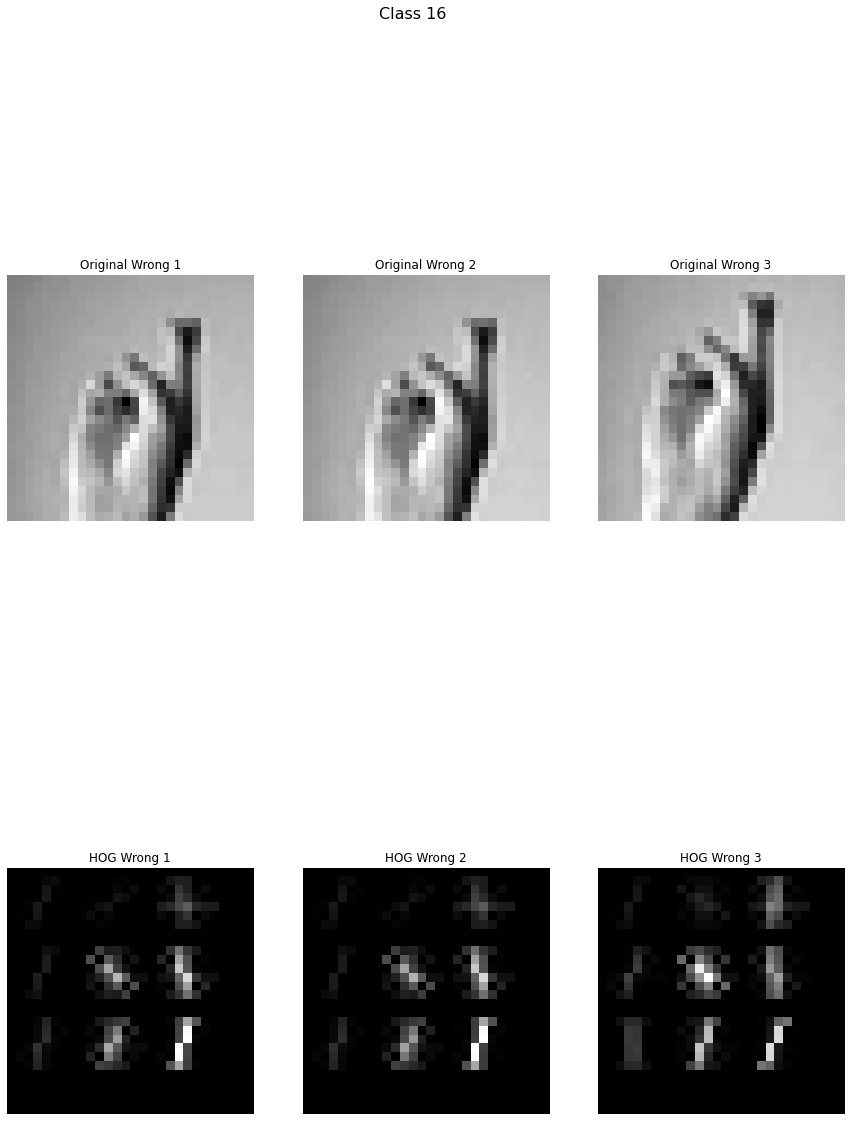

In [93]:
def visualize_wrongly_classified_images_of_class(class_idx, num_images_to_show=3):
    # Find indices of wrongly classified images
    wrong_indices = np.where((y_test == class_idx) & (y_test_pred != class_idx))[0]
    
    if len(wrong_indices) > num_images_to_show:
        wrong_indices = np.random.choice(wrong_indices, num_images_to_show, replace=False)

    # Visualize wrongly classified images
    if len(wrong_indices) > 0:
        visualize_hog_images(class_idx, wrong_indices, 'Wrong')

visualize_wrongly_classified_images_of_class(16)

Vizuelizacija dobro klasifikovanih slika:

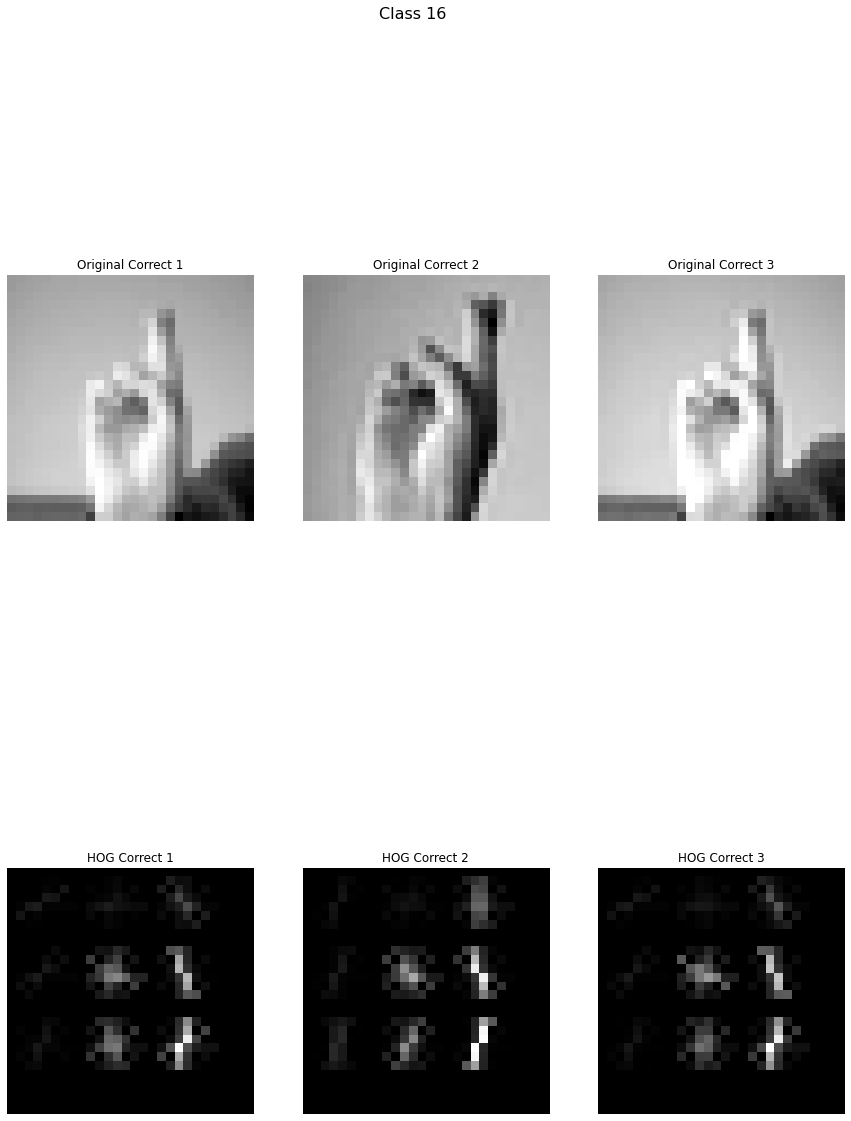

In [94]:
def visualize_correctly_classified_images_of_class(class_idx, num_images_to_show=3):
    # Find indices of correctly classified images
    correct_indices = np.where((y_test == class_idx) & (y_test_pred == class_idx))[0]
    
    if len(correct_indices) > num_images_to_show:
        correct_indices = np.random.choice(correct_indices, num_images_to_show, replace=False)

    # Visualize correctly classified images
    if len(correct_indices) > 0:
        visualize_hog_images(class_idx, correct_indices, 'Correct')
        
visualize_correctly_classified_images_of_class(16)